# Лабораторная работа № 5. Очистка данных

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Выполнить очистку данных о стекле: пропуски, недопустимые значения, дубликаты; сравнить стратегии заполнения пропусков и подготовить итоговую очищенную выборку.

## 1. Теоретическая часть

**1. Что такое очистка данных и почему она обязательна?** Очистка — обнаружение и устранение пропусков, выбросов/недопустимых значений, дубликатов и несогласованностей. Модели обучаются на том, что им дали: «мусор на входе — мусор на выходе». Многие алгоритмы вообще не принимают NaN, а ошибочные значения искажают статистики, масштабирование и обучение.

**2. Типы пропусков в числовых данных:** MCAR (полностью случайные, не зависят ни от чего), MAR (случайные при условии других признаков), MNAR (не случайные — пропуск зависит от самого значения). Важно и разделять «настоящие» пропуски и «скрытые» (нули, −1, 9999 как заглушки).

**3. Удаление строк и заполнение пропусков.** Удаление проще и не вносит выдуманных значений, но уменьшает выборку и может сместить её (если пропуски не случайны). Заполнение сохраняет объём данных, но вносит оценочные значения, сглаживает дисперсию и может исказить связи между признаками.

**4. Среднее или медиана.** Среднее — для симметричных распределений без выбросов; медиана — для скошенных распределений и при выбросах (устойчива). Для категориальных признаков используют моду или отдельную категорию «неизвестно».

**5. Риски некорректной очистки:** утечка информации из тестовой выборки (заполнение по всем данным до разбиения), удаление «выбросов», которые на деле являются редкими классами, смещение выборки, занижение дисперсии, подгонка под результат, невоспроизводимость (нет фиксированного порядка и параметров обработки).

## 2. Практическая часть

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

In [ ]:
print("Размерность:", df.shape)
display(df.dtypes.to_frame("dtype").T)
print("Числовые признаки:", FEATURES)
print("Категориальные: исходных нет; Type - код сорта (целевая, категориальная по смыслу)")

Размерность: (214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


Числовые признаки: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
Категориальные: исходных нет; Type - код сорта (целевая, категориальная по смыслу)


### 2.1. Базовый уровень

In [ ]:
print("Пропусков по столбцам:"); display(df.isna().sum().to_frame("NaN").T)
print("Всего пропусков:", int(df.isna().sum().sum()), "-> в исходных данных Kaggle пропусков нет")

Пропусков по столбцам:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
NaN,0,0,0,0,0,0,0,0,0,0


Всего пропусков: 0 -> в исходных данных Kaggle пропусков нет


В исходной выборке пропусков нет, поэтому для **демонстрации методов заполнения** ниже создана копия `demo`, в которую искусственно внесено ~8 % пропусков в числовых признаках (`MCAR`, `random_state=42`). Истинные значения известны — можно честно оценить качество заполнения.

In [ ]:
rng = np.random.default_rng(42)# Фиксируем генератор случайных чисел для воспроизводимости
demo = df.copy()# Делаем копию, чтобы не портить оригинал
# Для каждого числового признака случайно выбираем 8% строк и ставим там NaN
for col in FEATURES:
    idx = rng.choice(demo.index, size=int(0.08 * len(demo)), replace=False)
    demo.loc[idx, col] = np.nan
#Делаем то же самое для категориального столбца "Сорт" (15 случайных строк)
demo["Сорт"] = df["Type"].map(TYPE_NAMES)#категориальный признак для демонстрации
demo.loc[rng.choice(demo.index, size=15, replace=False), "Сорт"] = np.nan
print("Пропусков в demo:"); display(demo.isna().sum().to_frame("NaN").T)

Пропусков в demo:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Сорт
NaN,17,17,17,17,17,17,17,17,17,0,15


In [ ]:
# разделение признаков и базовое заполнение: числовые - медианой, категориальные - модой
num_cols = demo.select_dtypes("number").columns.drop("Type").tolist()
cat_cols = demo.select_dtypes(exclude="number").columns.tolist()
print("Числовые:", num_cols); print("Категориальные:", cat_cols)
demo_f = demo.copy()
# Числовые заполняем медианой
demo_f[num_cols] = demo_f[num_cols].fillna(demo_f[num_cols].median())
# Категориальные заполняем модой (самым частым значением)
for c_ in cat_cols:
    demo_f[c_] = demo_f[c_].fillna(demo_f[c_].mode()[0])
print("Пропусков после заполнения:", int(demo_f.isna().sum().sum()))

Числовые: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
Категориальные: ['Сорт']
Пропусков после заполнения: 0


In [ ]:
# --- Основной набор: проверка допустимых пределов ---
display(df[FEATURES].agg(["min", "max"]).T)
# физические пределы: массовая доля оксида 0-100 %, RI стекла 1.3-1.7
lim = df[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1) & df["RI"].between(1.3, 1.7)
print("Значений вне допустимых пределов:", int((~lim).sum()))
#Проверяем, что сумма оксидов близка к 100% (закон сохранения массы)
oxides = df[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].sum(axis=1)
print(f"Сумма оксидов на образец: min={oxides.min():.2f}, max={oxides.max():.2f} (должна быть около 100 %)")
# Ищем полные дубликаты строк
d1 = df[lim]                                                # удаление недопустимых (их нет)
print("Дубликатов:", int(d1.duplicated().sum()))# Выведет 1
display(d1[d1.duplicated(keep=False)])# Показывает эту строку
#Удаляем дубликаты и сбрасываем индексы
clean = d1.drop_duplicates().reset_index(drop=True)
print("Размер: до очистки", df.shape, "-> после очистки", clean.shape)

,min,max
RI,1.51115,1.53393
Na,10.73000,17.38000
Mg,0.00000,4.49000
Al,0.29000,3.50000
Si,69.81000,75.41000
K,0.00000,6.21000
Ca,5.43000,16.19000
Ba,0.00000,3.15000
Fe,0.00000,0.51000


Значений вне допустимых пределов: 0
Сумма оксидов на образец: min=99.02, max=100.10 (должна быть около 100 %)
Дубликатов: 1


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
38,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1
39,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


Размер: до очистки (214, 10) -> после очистки (213, 10)


In [ ]:
# контроль уровня 1
assert clean.isna().sum().sum() == 0 and clean.duplicated().sum() == 0
print("Пропусков:", int(clean.isna().sum().sum()), "| дубликатов:", int(clean.duplicated().sum()), "| вне допустимых пределов: 0")
# статистические «подозрительные» значения (по IQR) НЕ удаляем: это допустимые значения особых сортов (см. ЛР 3-4)
q1, q3 = clean[FEATURES].quantile(.25), clean[FEATURES].quantile(.75); iqr = q3 - q1
print("Статистических выбросов по IQR (сохранены):", int(((clean[FEATURES] < q1 - 1.5 * iqr) | (clean[FEATURES] > q3 + 1.5 * iqr)).sum().sum()))
clean.to_csv("glass_clean.csv", index=False)

Пропусков: 0 | дубликатов: 0 | вне допустимых пределов: 0
Статистических выбросов по IQR (сохранены): 137


### 2.2. Сравнение стратегий заполнения

,count,mean,std,min,50%,max
исходные (истина),214.0,1.445,0.499,0.29,1.360,3.50
с пропусками,197.0,1.439,0.481,0.29,1.360,3.04
среднее,214.0,1.439,0.461,0.29,1.430,3.04
интерполяция,214.0,1.435,0.467,0.29,1.375,3.04


RMSE восстановления Al: среднее = 0.6748, интерполяция = 0.6074


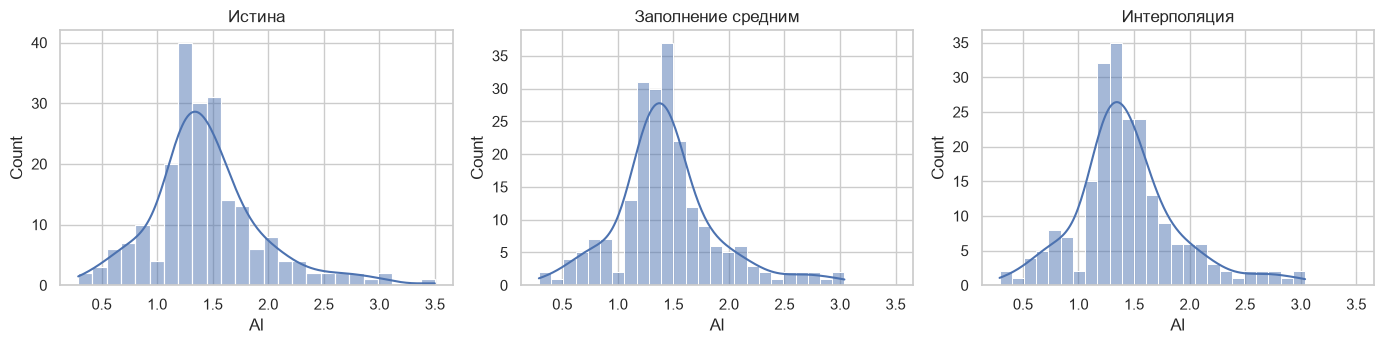

In [ ]:
feat = "Al"
# Создаем варианты заполнения
truth = df[feat]                                  # истинные значения
mask = demo[feat].isna()
mean_f = demo[feat].fillna(demo[feat].mean())
interp_f = demo[feat].interpolate(method="linear", limit_direction="both")
cmp = pd.DataFrame({"исходные (истина)": truth.describe(), "с пропусками": demo[feat].describe(),
                    "среднее": mean_f.describe(), "интерполяция": interp_f.describe()}).T[["count", "mean", "std", "min", "50%", "max"]]
display(cmp.round(3))
# Считаем ошибку (RMSE): насколько восстановленные значения отличаются от истинных
rmse = lambda a: np.sqrt(((a[mask] - truth[mask]) ** 2).mean())
print(f"RMSE восстановления {feat}: среднее = {rmse(mean_f):.4f}, интерполяция = {rmse(interp_f):.4f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for a, (t, s) in zip(ax, [("Истина", truth), ("Заполнение средним", mean_f), ("Интерполяция", interp_f)]):
    sns.histplot(s, bins=25, kde=True, ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

**Ответы.** Заполнение средним создаёт «пик» в центре распределения и занижает std, т. е. искажает форму распределения. Интерполяция опирается на соседние строки; в файле строки упорядочены по сорту, поэтому соседи похожи, и интерполяция точнее восстанавливает значения (меньше RMSE) и сохраняет разброс. Для последующего масштабирования предпочтительнее вариант, который меньше искажает среднее и std — здесь это интерполяция, но она осмысленна только при упорядоченных данных; в общем случае надёжнее многомерные методы (см. 2.3).

In [ ]:
print("Распределение категорий до очистки (с пропусками):")
before = demo["Сорт"].value_counts(dropna=False)
after = demo_f["Сорт"].value_counts()
true_ = df["Type"].map(TYPE_NAMES).value_counts()
display(pd.DataFrame({"истина": true_, "до заполнения": before, "после (мода)": after}).fillna(0).astype(int))

Распределение категорий до очистки (с пропусками):


,истина,до заполнения,после (мода)
контейнеры,13,12,12
окна авто (float),17,17,17
окна зданий (float),70,63,63
окна зданий (non-float),76,70,85
посуда,9,8,8
фары,29,29,29
NaN,0,15,0


Заполнение модой добавляет все 15 пропущенных значений к самой частой категории («окна зданий non-float»), то есть слегка завышает её долю и искажает распределение классов — для категориальной переменной лучше отдельная категория «неизвестно» либо восстановление по другим признакам.

### 2.3. Одномерное и многомерное восстановление

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer, KNNImputer
X_true = df[FEATURES].values
X_nan = demo[FEATURES].values
msk = np.isnan(X_nan)
res = {}
# Применяем 3 разных алгоритма к нашим искусственным пропускам
res["интерполяция"] = demo[FEATURES].interpolate(limit_direction="both").values
res["SimpleImputer (медиана)"] = SimpleImputer(strategy="median").fit_transform(X_nan)
res["KNNImputer (k=5)"] = KNNImputer(n_neighbors=5).fit_transform(X_nan)
res["IterativeImputer (многомерный)"] = IterativeImputer(random_state=42, max_iter=20).fit_transform(X_nan)
sd = df[FEATURES].std().values
tab = pd.DataFrame({k: [np.sqrt(np.nanmean(np.where(msk[:, j], (v[:, j] - X_true[:, j]) ** 2, np.nan))) / sd[j] for j in range(len(FEATURES))] for k, v in res.items()}, index=FEATURES)
display(tab.round(3).style.background_gradient(axis=1, cmap="Greens_r"))
print("Средняя нормированная ошибка (RMSE / std):"); display(tab.mean().round(3).sort_values().to_frame("ошибка"))

,интерполяция,SimpleImputer (медиана),KNNImputer (k=5),IterativeImputer (многомерный)
RI,0.629000,0.613000,0.356000,0.398000
Na,0.688000,1.218000,0.842000,0.724000
Mg,0.073000,1.045000,0.091000,0.349000
Al,1.217000,1.377000,1.101000,0.226000
Si,0.994000,0.995000,0.729000,0.143000
K,0.284000,0.520000,0.295000,0.448000
Ca,0.598000,0.828000,0.689000,0.484000
Ba,0.117000,0.821000,0.138000,0.718000
Fe,1.012000,0.791000,0.906000,0.826000


Средняя нормированная ошибка (RMSE / std):


,ошибка
IterativeImputer (многомерный),0.480
KNNImputer (k=5),0.572
интерполяция,0.624
SimpleImputer (медиана),0.912


In [ ]:
st = pd.DataFrame({k: pd.DataFrame(v, columns=FEATURES).std() for k, v in res.items()})
st["истина"] = df[FEATURES].std()
print("Стандартное отклонение признаков после восстановления:"); display(st.round(3))

Стандартное отклонение признаков после восстановления:


,интерполяция,SimpleImputer (медиана),KNNImputer (k=5),IterativeImputer (многомерный),истина
RI,0.003,0.003,0.003,0.003,0.003
Na,0.791,0.766,0.779,0.814,0.817
Mg,1.443,1.408,1.444,1.434,1.442
Al,0.467,0.462,0.471,0.503,0.499
Si,0.758,0.743,0.752,0.770,0.775
K,0.650,0.647,0.650,0.655,0.652
Ca,1.408,1.392,1.395,1.408,1.423
Ba,0.496,0.487,0.494,0.487,0.497
Fe,0.097,0.097,0.096,0.096,0.097


**Сравнение.** Наименьшую ошибку даёт многомерный IterativeImputer (≈ 0.48 от std признака), затем KNNImputer (≈ 0.57) и интерполяция (≈ 0.62); одномерное заполнение медианой самое грубое (≈ 0.91) и «схлопывает» разброс (std после заполнения заметно ниже истинного). Многомерные методы учитывают связи между признаками (RI–Ca, Mg–Al) и поэтому точнее. В реальных данных Glass пропусков нет, поэтому в пайплайне эти методы не применяются, но готовы к использованию.

### Вывод

После первичного анализа описательной статистики (ЛР 3–4) в данных Glass были проверены пропуски, допустимые диапазоны и дубликаты. Пропусков в исходной выборке нет, значения всех оксидов лежат в физически допустимых пределах 0–100 %, суммы оксидов близки к 100 %, а показатель преломления — в диапазоне 1.511–1.534. Единственная выявленная проблема — один полностью дублирующийся образец (две идентичные строки сорта 1), который нельзя оставлять, потому что он искусственно повышает вес объекта и может попасть и в обучающую, и в тестовую выборку, завышая качество. Статистические выбросы (особенно Ba, K, Fe) не удалялись, так как они принадлежат реальным сортам стекла и несут информацию, а их удаление привело бы к потере малых классов. Для демонстрации методов в копию данных были внесены пропуски: заполнение средним и медианой занижает дисперсию, интерполяция по упорядоченным строкам и многомерные методы (KNN, IterativeImputer) сохраняют структуру данных лучше. Итоговая выборка содержит 213 строк и 9 признаков + целевую переменную, без пропусков и дубликатов. Она пригодна для масштабирования, поскольку все признаки числовые и не содержат NaN, которые сломали бы расчёт среднего и std. Она пригодна для кодирования, так как единственная категориальная переменная (сорт) имеет чистый и непротиворечивый набор значений. Процедура воспроизводима: она оформлена функцией `clean_glass()`, имеет фиксированный `random_state` и результат сохраняется в `glass_clean.csv`. Эта версия данных используется во всех следующих лабораторных работах.